In [23]:
from datasets import load_dataset

df = load_dataset("eliel2003/student-burnout-analysis-2026", split="train").to_pandas()
print(df.shape)

(1000000, 20)


In [24]:
print(df.dtypes)
print(df.isna().sum())
print(df["risk_level"].value_counts(normalize=True))
print(df.describe().T)

age                       int64
gender                      str
academic_year             int64
study_hours_per_day     float64
exam_pressure           float64
academic_performance    float64
stress_level            float64
anxiety_score           float64
depression_score        float64
sleep_hours             float64
physical_activity       float64
social_support          float64
screen_time             float64
internet_usage          float64
financial_stress        float64
family_expectation      float64
burnout_score           float64
mental_health_index     float64
risk_level                  str
dropout_risk            float64
dtype: object
age                     0
gender                  0
academic_year           0
study_hours_per_day     0
exam_pressure           0
academic_performance    0
stress_level            0
anxiety_score           0
depression_score        0
sleep_hours             0
physical_activity       0
social_support          0
screen_time             0
internet

In [25]:
y_num = df["risk_level"].map({"Low": 0, "Medium": 1, "High": 2})
print(df.select_dtypes("number").corrwith(y_num).sort_values())

mental_health_index    -0.629438
sleep_hours            -0.287203
social_support         -0.180818
physical_activity      -0.085685
age                    -0.000618
screen_time            -0.000417
internet_usage         -0.000385
academic_year           0.000650
academic_performance    0.044945
family_expectation      0.167409
financial_stress        0.231053
study_hours_per_day     0.260212
exam_pressure           0.336580
anxiety_score           0.521974
depression_score        0.532063
stress_level            0.586117
dropout_risk            0.591442
burnout_score           0.828259
dtype: float64


In [26]:
print(df.groupby("risk_level")[["burnout_score", "mental_health_index",
                                "stress_level", "dropout_risk"]].mean())

            burnout_score  mental_health_index  stress_level  dropout_risk
risk_level                                                                
High             6.725338             4.164482      7.584744      4.348158
Low              1.044050             7.467992      3.714342      0.901961
Medium           4.041871             5.657880      5.884788      2.601497


In [27]:
TARGET = "risk_level"
OUTCOMES = ["stress_level", "anxiety_score", "depression_score",
            "burnout_score", "mental_health_index", "dropout_risk"]

df = df.drop_duplicates().dropna(subset=[TARGET])
X = df.drop(columns=[TARGET] + OUTCOMES)
y = df[TARGET]
print(X.columns.tolist())

['age', 'gender', 'academic_year', 'study_hours_per_day', 'exam_pressure', 'academic_performance', 'sleep_hours', 'physical_activity', 'social_support', 'screen_time', 'internet_usage', 'financial_stress', 'family_expectation']


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [29]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(classification_report(y_test, baseline.predict(X_test), zero_division=0))

              precision    recall  f1-score   support

        High       0.00      0.00      0.00      3016
         Low       0.77      1.00      0.87    153329
      Medium       0.00      0.00      0.00     43655

    accuracy                           0.77    200000
   macro avg       0.26      0.33      0.29    200000
weighted avg       0.59      0.77      0.67    200000



In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

preprocess = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

model = Pipeline([
    ("prep", preprocess),
    ("clf", HistGradientBoostingClassifier(random_state=42)),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','gender','academic_year',...,'internet_usage','financial_stress', 'family_expectation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

              precision    recall  f1-score   support

        High       0.49      0.11      0.18      3016
         Low       0.86      0.93      0.90    153329
      Medium       0.62      0.48      0.54     43655

    accuracy                           0.82    200000
   macro avg       0.66      0.51      0.54    200000
weighted avg       0.80      0.82      0.81    200000



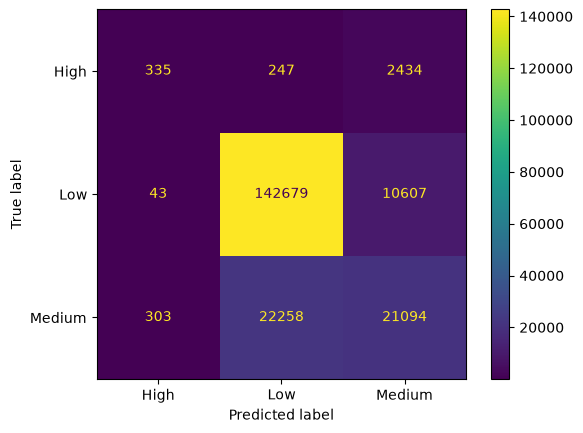

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

pred = model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred)

In [44]:
from sklearn.inspection import permutation_importance

sample = X_test.sample(5000, random_state=42)
r = permutation_importance(model, sample, y_test.loc[sample.index],
                           n_repeats=3, random_state=42)
for name, score in sorted(zip(sample.columns, r.importances_mean), key=lambda t: -t[1]):
    print(f"{name}: {score:.3f}")

exam_pressure: 0.072
sleep_hours: 0.056
financial_stress: 0.035
social_support: 0.023
family_expectation: 0.020
physical_activity: 0.005
gender: 0.000
screen_time: -0.000
age: -0.000
internet_usage: -0.000
academic_year: -0.000
study_hours_per_day: -0.000
academic_performance: -0.001


In [45]:
from sklearn.metrics import recall_score

for col in ["gender", "academic_year"]:
    print("---", col)
    for g in X_test[col].dropna().unique():
        m = (X_test[col] == g).values
        if m.sum() > 100:
            print(g, m.sum(), round(recall_score(
                y_test[m], pred[m], average="macro", zero_division=0), 3))

--- gender
Female 95819 0.507
Male 96096 0.51
Other 8085 0.495
--- academic_year
1 50167 0.508
4 49999 0.514
3 49954 0.505
2 49880 0.507


In [46]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor

Xs = df.drop(columns=["stress_level", "anxiety_score", "depression_score",
                      "burnout_score", "mental_health_index",
                      "dropout_risk", "risk_level"])
ys = df["stress_level"]
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.2, random_state=42)

reg = Pipeline([("prep", preprocess), ("reg", HistGradientBoostingRegressor(random_state=42))])
reg.fit(Xs_tr, ys_tr)
print("model MAE:", mean_absolute_error(ys_te, reg.predict(Xs_te)))
print("baseline MAE:", mean_absolute_error(ys_te, DummyRegressor().fit(Xs_tr, ys_tr).predict(Xs_te)))

model MAE: 0.7980732294779174
baseline MAE: 1.345494632886197


In [47]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import numpy as np

proba = model.predict_proba(X_test)
hi = list(model.classes_).index("High")
y_hi = (y_test == "High").astype(int)

print("PR-AUC for High:", round(average_precision_score(y_hi, proba[:, hi]), 3))

prec, rec, thr = precision_recall_curve(y_hi, proba[:, hi])
for t in [0.3, 0.5, 0.7, 0.9]:
    pred_hi = proba[:, hi] >= t
    tp = (pred_hi & (y_hi == 1)).sum()
    print(f"threshold {t}: flagged {pred_hi.sum()}, precision {tp/max(pred_hi.sum(),1):.2f}, recall {tp/y_hi.sum():.2f}")

PR-AUC for High: 0.271
threshold 0.3: flagged 1750, precision 0.39, recall 0.23
threshold 0.5: flagged 604, precision 0.51, recall 0.10
threshold 0.7: flagged 194, precision 0.59, recall 0.04
threshold 0.9: flagged 18, precision 0.44, recall 0.00


In [48]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

m = clone(model).fit(X_fit, y_fit)
hi = list(m.classes_).index("High")
pv = m.predict_proba(X_val)[:, hi]
yv = (y_val == "High").astype(int)

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    f = pv >= t
    tp = (f & (yv == 1)).sum()
    print(t, "flagged", f.sum(), "precision", round(tp / max(f.sum(), 1), 2),
          "recall", round(tp / yv.sum(), 2))

0.3 flagged 1417 precision 0.39 recall 0.23
0.4 flagged 880 precision 0.44 recall 0.16
0.5 flagged 549 precision 0.5 recall 0.11
0.6 flagged 317 precision 0.56 recall 0.07
0.7 flagged 169 precision 0.6 recall 0.04


In [49]:
THRESH = 0.5   # EDIT: your chosen value

pt = m.predict_proba(X_test)[:, hi]
flag = pt >= THRESH
yt = (y_test == "High").astype(int)
tp = (flag & (yt == 1)).sum()

print("flagged:", flag.sum(), f"({flag.mean():.1%} of students)")
print("precision:", round(tp / flag.sum(), 2))
print("recall:", round(tp / yt.sum(), 2))

flagged: 649 (0.3% of students)
precision: 0.48
recall: 0.1


In [50]:
from sklearn.metrics import roc_auc_score
proba = model.predict_proba(X_test)
hi = list(model.classes_).index("High")
print("ROC-AUC for High:", roc_auc_score((y_test == "High").astype(int), proba[:, hi]))

ROC-AUC for High: 0.9471353592412305


In [51]:
m2 = Pipeline([("prep", preprocess),
               ("clf", HistGradientBoostingClassifier(random_state=42))]).fit(X_train, y_train)
hi2 = list(m2.classes_).index("High")
print(average_precision_score((y_test == "High").astype(int), m2.predict_proba(X_test)[:, hi2]))

0.2711705318113921


In [52]:
cols = ["burnout_score", "mental_health_index", "stress_level",
        "anxiety_score", "depression_score", "dropout_risk"]
Xo = df[cols]
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(Xo, df["risk_level"], test_size=0.2,
                                              random_state=42, stratify=df["risk_level"])
chk = HistGradientBoostingClassifier(random_state=42).fit(Xo_tr, yo_tr)
print(classification_report(yo_te, chk.predict(Xo_te), zero_division=0))

              precision    recall  f1-score   support

        High       0.97      1.00      0.98      3016
         Low       1.00      1.00      1.00    153329
      Medium       1.00      1.00      1.00     43655

    accuracy                           1.00    200000
   macro avg       0.99      1.00      0.99    200000
weighted avg       1.00      1.00      1.00    200000



In [53]:
from sklearn.tree import DecisionTreeClassifier, export_text

tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xo_tr, yo_tr)
print(export_text(tree, feature_names=cols))
print("accuracy:", tree.score(Xo_te, yo_te))

|--- burnout_score <= 3.00
|   |--- class: Low
|--- burnout_score >  3.00
|   |--- burnout_score <= 6.00
|   |   |--- class: Medium
|   |--- burnout_score >  6.00
|   |   |--- class: High

accuracy: 1.0


In [54]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score

for c in ["burnout_score", "mental_health_index"]:
    r = Pipeline([("prep", clone(preprocess)),
                  ("reg", HistGradientBoostingRegressor(random_state=42))])
    r.fit(X_train, df.loc[X_train.index, c])
    print(c, "R²:", round(r2_score(df.loc[X_test.index, c], r.predict(X_test)), 3))

burnout_score R²: 0.547
mental_health_index R²: 0.595


In [55]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score, average_precision_score

yb_fit = df.loc[X_fit.index, "burnout_score"]
yb_val = df.loc[X_val.index, "burnout_score"]
yb_test = df.loc[X_test.index, "burnout_score"]

rb = Pipeline([("prep", clone(preprocess)),
               ("reg", HistGradientBoostingRegressor(random_state=42))])
rb.fit(X_fit, yb_fit)

pv = rb.predict(X_val)
print("val R²:", round(r2_score(yb_val, pv), 3), " MAE:", round(mean_absolute_error(yb_val, pv), 3))

# Ranking quality for High (true burnout_score > 6), no minus sign needed
is_high = (yb_val > 6).astype(int)
print("PR-AUC for High:", round(average_precision_score(is_high, pv), 3), "(your classifier: 0.234)")

# Threshold on the predicted score
for t in [4.5, 5.0, 5.5, 6.0]:
    f = pv >= t
    tp = (f & (is_high == 1)).sum()
    print(t, "flagged", f.sum(), "precision", round(tp / max(f.sum(), 1), 2),
          "recall", round(tp / is_high.sum(), 2))

val R²: 0.548  MAE: 0.869
PR-AUC for High: 0.308 (your classifier: 0.234)
4.5 flagged 4644 precision 0.27 recall 0.51
5.0 flagged 2101 precision 0.37 recall 0.33
5.5 flagged 790 precision 0.5 recall 0.16
6.0 flagged 242 precision 0.67 recall 0.07


In [58]:
Xall = df.drop(columns=["burnout_score", "risk_level"])
num_all = Xall.select_dtypes(include="number").columns
cat_all = Xall.select_dtypes(exclude="number").columns

pre_all = ColumnTransformer([
    ("num", "passthrough", num_all),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_all),
])
rall = Pipeline([("prep", pre_all),
                 ("reg", HistGradientBoostingRegressor(random_state=42))])
rall.fit(Xall.loc[X_fit.index], yb_fit)
print("R² using ALL other columns:",
      round(r2_score(yb_val, rall.predict(Xall.loc[X_val.index])), 3))

R² using ALL other columns: 0.77


In [59]:
pall = rall.predict(Xall.loc[X_val.index])
is_high = (yb_val > 6).astype(int)
print("PR-AUC (all columns):", round(average_precision_score(is_high, pall), 3))
print("PR-AUC (inputs only):", 0.308)

PR-AUC (all columns): 0.58
PR-AUC (inputs only): 0.308


In [60]:
THRESH = 5.5   # EDIT: your choice, from the validation table
pt = rb.predict(X_test)
is_high_t = (yb_test > 6).astype(int)
flag = pt >= THRESH
tp = (flag & (is_high_t == 1)).sum()
print("flagged:", flag.sum(), f"({flag.mean():.1%})")
print("precision:", round(tp / max(flag.sum(), 1), 2))
print("recall:", round(tp / is_high_t.sum(), 2))
print("test R²:", round(r2_score(yb_test, pt), 3), " test MAE:", round(mean_absolute_error(yb_test, pt), 3))

flagged: 968 (0.5%)
precision: 0.52
recall: 0.17
test R²: 0.547  test MAE: 0.869


In [61]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, average_precision_score
import numpy as np

SELF_REPORT = ["stress_level", "anxiety_score", "depression_score"]

# Simulate students who skip the check-in: blank it out for ~40% of rows
rng = np.random.default_rng(42)
Xc = df.drop(columns=["burnout_score", "risk_level", "mental_health_index", "dropout_risk"]).copy()
skip = rng.random(len(Xc)) < 0.4
Xc.loc[skip, SELF_REPORT] = np.nan

num_c = Xc.select_dtypes(include="number").columns
cat_c = Xc.select_dtypes(exclude="number").columns
pre_c = ColumnTransformer([("num", "passthrough", num_c),
                           ("cat", OneHotEncoder(handle_unknown="ignore"), cat_c)])
combined = Pipeline([("prep", pre_c),
                     ("reg", HistGradientBoostingRegressor(random_state=42))])
combined.fit(Xc.loc[X_fit.index], yb_fit)

pc = combined.predict(Xc.loc[X_val.index])
is_high = (yb_val > 6).astype(int)
print("R² overall:", round(r2_score(yb_val, pc), 3))
print("PR-AUC overall:", round(average_precision_score(is_high, pc), 3))

# Compare students who did vs did not complete the check-in
done = ~skip[X_val.index.map(Xc.index.get_loc)]
for label, m in [("with check-in", done), ("without", ~done)]:
    print(label, "R²:", round(r2_score(yb_val[m], pc[m]), 3))

R² overall: 0.659
PR-AUC overall: 0.438
with check-in R²: 0.736
without R²: 0.544
